Loading fallback: /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_t_MAMS3SM_z0.001-m1_rp12p6_a0p2.txt
Loading energy:   /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_E_MAMS3SM_z0.001-m1_rp12p6_a0p2.txt
Loading fallback: /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_t_MAMS3SM_z0.006-m1_rp15p88_a0p2.txt
Loading energy:   /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_E_MAMS3SM_z0.006-m1_rp15p88_a0p2.txt
Loading fallback: /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_t_MAMS3SM-m1_rp18p2_a0p2.txt
Loading energy:   /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_E_MAMS3SM-m1_rp18p2_a0p2.txt
Loading fallback: /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_t_MAMS3SM_z0p03-m1_rp20p18_a0p2.txt
Loading energy:   /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_E_MAMS3SM_z0p03-m1_rp20p18_a0p2.txt


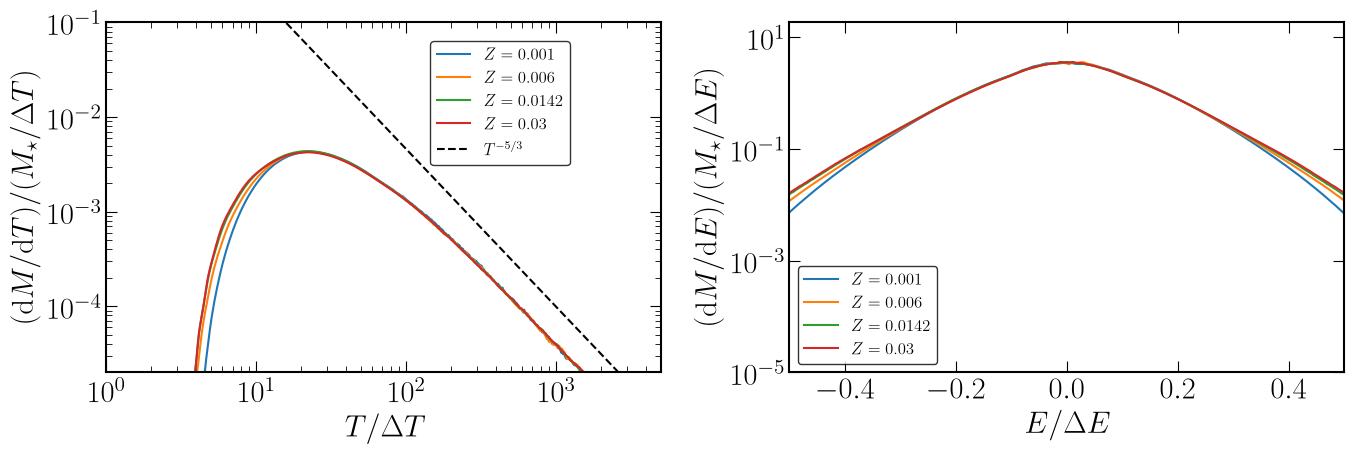

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path

# --------------------------------------------------
# Paths
# --------------------------------------------------

fallback_dir = Path(
    "/Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data"
)

# --------------------------------------------------
# Models
# --------------------------------------------------

models = {
    r"$Z=0.001$":  "MAMS3SM_z0.001-m1_rp12p6",
    r"$Z=0.006$":  "MAMS3SM_z0.006-m1_rp15p88",
    r"$Z=0.0142$": "MAMS3SM-m1_rp18p2",
    r"$Z=0.03$":   "MAMS3SM_z0p03-m1_rp20p18",
}

# --------------------------------------------------
# Load data
# --------------------------------------------------

fallback_data = {}
energy_data = {}

for label, adden in models.items():

    # -----------------------------
    # Fallback-rate file
    # -----------------------------
    t_filename = fallback_dir / f"rel_p_t_{adden}_a0p2.txt"

    print(f"Loading fallback: {t_filename}")

    with open(t_filename, "r") as f:
        t_data = json.load(f)

    fallback_data[label] = {
        k: np.array(v) for k, v in t_data.items()
    }

    # -----------------------------
    # Energy-distribution file
    # -----------------------------
    E_filename = fallback_dir / f"rel_p_E_{adden}_a0p2.txt"

    print(f"Loading energy:   {E_filename}")

    with open(E_filename, "r") as f:
        E_data = json.load(f)

    energy_data[label] = {
        k: np.array(v) for k, v in E_data.items()
    }

# --------------------------------------------------
# Plot style
# --------------------------------------------------

plt.style.use(
    "/Users/mchau/mesa_tutorial/PerTDE/Relativistic/plot_style.mplstyle"
)

plt.rc("text", usetex=True)

# ==================================================
# CREATE ONE FIGURE WITH TWO HORIZONTAL PANELS
# ==================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# ==================================================
# 1. FALLBACK RATE — LEFT
# ==================================================

for label, data in fallback_data.items():

    ax1.plot(
        data["x"],
        data["y"],
        label=label
    )

# T^(-5/3) reference
bins_T = np.logspace(0, 6, 200)

ax1.plot(
    bins_T,
    10 * bins_T**(-5/3),
    "k--",
    label=r"$T^{-5/3}$"
)

ax1.set_xscale("log")
ax1.set_yscale("log")

ax1.set_xlabel(r"$T / \Delta T$")
ax1.set_ylabel(
    r"$(\mathrm{d}M/\mathrm{d}T) / (M_\star / \Delta T)$"
)

ax1.set_xlim(1, 5000)
ax1.set_ylim(2e-5, 0.1)

ax1.legend(
    loc="upper left",
    bbox_to_anchor=(0.57, 0.97),
    frameon=True,
    edgecolor="black",
    facecolor="white",
    fontsize=12
)

# ==================================================
# 2. ENERGY DISTRIBUTION — RIGHT
# ==================================================

for label, data in energy_data.items():

    ax2.plot(
        data["x"],
        data["y"],
        label=label
    )

ax2.set_yscale("log")

ax2.set_xlabel(r"$E / \Delta E$")
ax2.set_ylabel(
    r"$(\mathrm{d}M/\mathrm{d}E) / (M_\star / \Delta E)$"
)

ax2.set_xlim(-0.5, 0.5)
ax2.set_ylim(1e-5, None)

ax2.legend(
    loc="best",
    frameon=True,
    edgecolor="black",
    facecolor="white",
    fontsize=12
)

# --------------------------------------------------
# Final layout
# --------------------------------------------------

plt.tight_layout()
plt.show()

In [10]:
for label, data in energy_data.items():
    print(label)
    print("  x first 5:", data["x"][:5])
    print("  y first 5:", data["y"][:5])
    print("  y max:", np.max(data["y"]))
    print("  number of points:", len(data["y"]))
labels = list(energy_data.keys())

for i in range(len(labels)):
    for j in range(i + 1, len(labels)):

        a = energy_data[labels[i]]
        b = energy_data[labels[j]]

        same_x = np.array_equal(a["x"], b["x"])
        same_y = np.array_equal(a["y"], b["y"])

        max_diff = np.max(np.abs(a["y"] - b["y"]))

        print(
            labels[i], "vs", labels[j],
            "\n  x identical:", same_x,
            "\n  y identical:", same_y,
            "\n  max |Δy|:", max_diff,
            "\n"
        )

$Z=0.001$
  x first 5: [-1.997998   -1.99399399 -1.98998999 -1.98598599 -1.98198198]
  y first 5: [0. 0. 0. 0. 0.]
  y max: 4.165528875041999
  number of points: 999
$Z=0.006$
  x first 5: [-1.997998   -1.99399399 -1.98998999 -1.98598599 -1.98198198]
  y first 5: [0. 0. 0. 0. 0.]
  y max: 4.136353441605414
  number of points: 999
$Z=0.0142$
  x first 5: [-1.997998   -1.99399399 -1.98998999 -1.98598599 -1.98198198]
  y first 5: [4.64505957e-12 4.40356330e-12 4.55515610e-12 4.52646866e-12
 4.43345885e-12]
  y max: 3.5892804125182094
  number of points: 999
$Z=0.03$
  x first 5: [-1.997998   -1.99399399 -1.98998999 -1.98598599 -1.98198198]
  y first 5: [5.80004825e-12 5.37029528e-12 5.56032837e-12 5.34437770e-12
 5.48048070e-12]
  y max: 3.617503694306948
  number of points: 999
$Z=0.001$ vs $Z=0.006$ 
  x identical: True 
  y identical: False 
  max |Δy|: 0.08552037236657384 

$Z=0.001$ vs $Z=0.0142$ 
  x identical: True 
  y identical: False 
  max |Δy|: 0.6617046447875294 

$Z=0.001$ v

In [10]:
from pathlib import Path

base = Path("/Users/mchau/mesa_tutorial/results/mams_profiles")

models = {
    r"$Z=0.001$":
        base / "MAMS3Msun_Z0p0010/MAMS3Msun_Z0p0010.profile",

    r"$Z=0.0142$":
        base / "MAMS3Msun_Z0p0142/MAMS3Msun_Z0p0142.profile",

    r"$Z=0.03$":
        base / "MAMS3Msun_Z0p0300/MAMS3Msun_Z0p0300.profile",
}

for label, path in models.items():
    print(label, path)
    print("Exists:", path.exists())

$Z=0.001$ /Users/mchau/mesa_tutorial/results/mams_profiles/MAMS3Msun_Z0p0010/MAMS3Msun_Z0p0010.profile
Exists: True
$Z=0.0142$ /Users/mchau/mesa_tutorial/results/mams_profiles/MAMS3Msun_Z0p0142/MAMS3Msun_Z0p0142.profile
Exists: True
$Z=0.03$ /Users/mchau/mesa_tutorial/results/mams_profiles/MAMS3Msun_Z0p0300/MAMS3Msun_Z0p0300.profile
Exists: True


In [12]:
for label, path in paths.items():
    print(f"\n--- {label} ---")
    with open(path, "r") as f:
        for _ in range(10):
            print(f.readline().rstrip())


--- Z=0.001 ---
                                       1                                        2                                        3                                        4                                        5                                        6                                        7                                        8                                        9                                       10                                       11                                       12                                       13                                       14                                       15                                       16                                       17                                       18                                       19                                       20                                       21                                       22                                       23                                       24

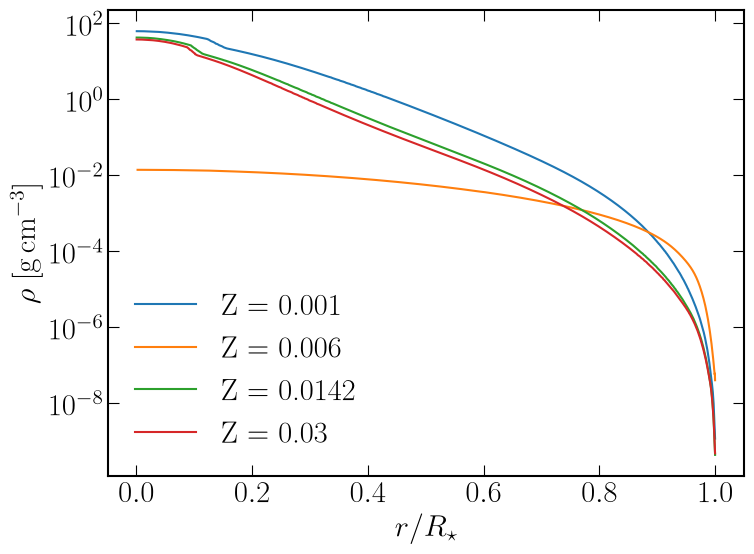

NameError: name 'Z' is not defined

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

profiles = {
    "Z = 0.001": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0010/MAMS3Msun_Z0p0010.profile"
    ),
    "Z = 0.006": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0060/MAMS3Msun_Z0p0060.profile"
    ),
    "Z = 0.0142": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0142/MAMS3Msun_Z0p0142.profile"
    ),
    "Z = 0.03": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0300/MAMS3Msun_Z0p0300.profile"
    ),
}

plt.figure(figsize=(8, 6))

for label, path in profiles.items():

    # The first 3 lines are the header; line 4 starts the profile data.
    data = np.loadtxt(path, skiprows=6)

    # Columns from your profile:
    # 0 = zone
    # 1 = mass
    # 2 = logR
    # 3 = logT
    # 4 = logRho
    # 5 = logP

    r = 10**data[:, 2]
    rho = 10**data[:, 4]

    Rstar = r.max()

    plt.plot(r / Rstar, rho, label=label)

plt.yscale("log")
plt.xlabel(r"$r/R_\star$")
plt.ylabel(r"$\rho\;[\mathrm{g\,cm^{-3}}]$")
plt.legend()
plt.tight_layout()
plt.show()
print("Z =", Z)
print("Mass =", mass)
print("Radius =", radius)
print("Age =", age)
print("Central H =", center_h1)

## plt.figure(figsize=(8, 6))

for label, path in profiles.items():

    data = np.loadtxt(path, skiprows=6)

    r = 10**data[:, 2]
    m = data[:, 1]

    Rstar = r.max()
    Mstar = m.max()

    plt.plot(r / Rstar, m / Mstar, label=label)

plt.xlabel(r"$r/R_\star$")
plt.ylabel(r"$M(<r)/M_\star$")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
for label, path in profiles.items():
    print("\n" + "=" * 60)
    print(label)
    print("=" * 60)

    with open(path, "r") as f:
        for i in range(10):
            line = f.readline()
            print(line.rstrip())


Z = 0.001
                                       1                                        2                                        3                                        4                                        5                                        6                                        7                                        8                                        9                                       10                                       11                                       12                                       13                                       14                                       15                                       16                                       17                                       18                                       19                                       20                                       21                                       22                                       23                                       24      